# Build Your First Neural Network (Keras)
Architecture: Dense(16, relu) -> Dense(8, relu) -> Dense(1, sigmoid)

**Before running:** set `FILE` and `TARGET` in the first code cell.

## 1. Load the data

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os
os.environ["KERAS_BACKEND"] = "jax"   # must come before importing keras

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import keras
from keras import layers

# ---- CHANGE THESE TWO LINES ----
FILE = "BankNote_Authentication.csv"   # name of the file you uploaded to Colab
TARGET = None            # target column name, or None to use the last column
# --------------------------------

df = pd.read_csv(FILE).dropna()
if TARGET is None:
    TARGET = df.columns[-1]

print("Shape:", df.shape)
print("Target column:", TARGET)
df.head()

Shape: (1372, 5)
Target column: class


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## 2. Prepare features, train/test split, scaling

In [6]:
# y: turn target into 0/1 (works for text labels like Yes/No too)
y = pd.factorize(df[TARGET])[0]

# X: all other columns, text columns become 0/1 columns
X = pd.get_dummies(df.drop(columns=[TARGET])).astype("float32")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale so all features are on a similar range (helps training)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1097, 4)  Test: (275, 4)


## 3. Build and compile the model

In [7]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

## 4. Train (30 epochs)

In [8]:
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1,
)

Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.6055 - loss: 0.6546 - val_accuracy: 0.6864 - val_loss: 0.6132
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8392 - loss: 0.5685 - val_accuracy: 0.8818 - val_loss: 0.5367
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9008 - loss: 0.4938 - val_accuracy: 0.9045 - val_loss: 0.4706
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9236 - loss: 0.4248 - val_accuracy: 0.9273 - val_loss: 0.4047
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9453 - loss: 0.3560 - val_accuracy: 0.9227 - val_loss: 0.3396
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9555 - loss: 0.2934 - val_accuracy: 0.9364 - val_loss: 0.2828
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9647 - loss: 0.2415 - val_accuracy: 0.9500 - val_loss: 0.2362
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9658 - loss: 0.1987 - val_accuracy: 0.9591 - val_loss

## 5. Test accuracy

In [9]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Final test accuracy: {test_acc:.4f}")

Final test accuracy: 0.9964


## 6. Training vs. validation loss

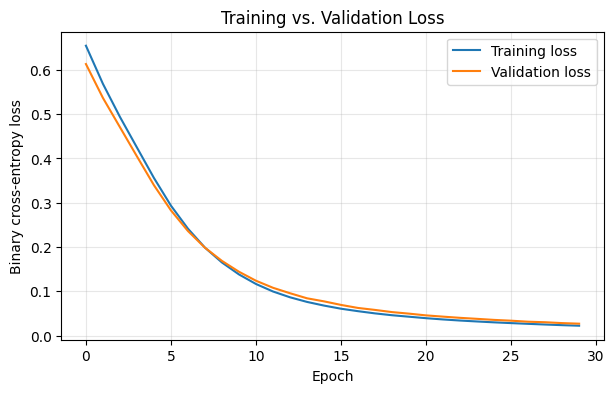

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Forward propagation vs. backpropagation

In forward propagation, each batch of data flows through the layers: every neuron multiplies its inputs by weights, adds a bias, applies ReLU (or sigmoid at the end), and the final output is a probability that gets compared to the true label using binary cross-entropy to get a loss. In backpropagation, the model works backwards from that loss using the chain rule to figure out how much each weight and bias contributed to the error, and Adam then nudges every weight a small step in the direction that reduces the loss. Repeating this over all batches each epoch is how the network slowly gets better, like taking a shot, seeing how far off you were, and adjusting your aim a little each time.